# Chapter 3: Polynomial Regression Exercise 🚗

## Learning Objectives 🎯
After completing this exercise, you will be able to:
- Apply polynomial regression to real-world automotive data
- Compare linear and polynomial models in practice
- Choose the best features for predicting fuel efficiency
- Find the optimal polynomial degree for your model
- Make practical predictions about car performance

Let's put your polynomial regression skills to work with a real-world automotive challenge! 🔧

In [31]:
%reset
low_memory=False

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

Nothing done.


## Problem setting

### Understanding Fuel Efficiency 🚗

In the automotive industry, one of the most important measures is **MPG (Miles Per Gallon)**:
- 🛣️ How many miles a car can drive on one gallon of fuel
- 📈 Higher MPG = Better fuel efficiency
- 💰 Higher MPG = Lower fuel costs for drivers
- 🌍 Higher MPG = Better for the environment

#### Why MPG Matters 🤔
1. **For Consumers:**
   - Save money on fuel
   - Make environmentally conscious choices
   - Plan long-distance trips

2. **For Manufacturers:**
   - Meet government regulations
   - Attract eco-conscious buyers
   - Compete in the market

3. **For Environment:**
   - Reduce carbon emissions
   - Conserve fossil fuels
   - Lower environmental impact

Our challenge: Can we predict a car's MPG based on its characteristics? 🎯

## Model

In [32]:
df=pd.read_csv("/Users/mohammedsadmanuddin/data science fund/Polynomial regression/Auto.csv")
df.head(10)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
5,15.0,8,429.0,198,4341,10.0,70,1,ford galaxie 500
6,14.0,8,454.0,220,4354,9.0,70,1,chevrolet impala
7,14.0,8,440.0,215,4312,8.5,70,1,plymouth fury iii
8,14.0,8,455.0,225,4425,10.0,70,1,pontiac catalina
9,15.0,8,390.0,190,3850,8.5,70,1,amc ambassador dpl


### 🔍 Data Analysis: First Steps

#### Question 1: Exploring Our Data
Look at the dataset carefully. We need to identify any columns that might cause problems:

1. **What to Look For:**
   - Which columns contain numbers? ✅
   - Which columns contain text? ❌
   - Why might text be problematic?

2. **Think About:**
   - Can regression work with text data?
   - How might we handle text data?
   - Would it be worth the effort?

3. **Advanced Consideration:**
   - What is one-hot encoding?
   - When is it useful?
   - Why might it not work here?

analysis:
- car name contains text...so it needs to be droped
- regression need numerical values as input...text data can be transfer into numerical values but the car name column have less predictive values so its better to drop it

##### Question 2: Drop the extra column.

In [15]:
df=df.drop(columns=["car name"])

In [16]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130,3504,12.0,70,1
1,15.0,8,350.0,165,3693,11.5,70,1
2,18.0,8,318.0,150,3436,11.0,70,1
3,16.0,8,304.0,150,3433,12.0,70,1
4,17.0,8,302.0,140,3449,10.5,70,1
...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1
394,44.0,4,97.0,52,2130,24.6,82,2
395,32.0,4,135.0,84,2295,11.6,82,1
396,28.0,4,120.0,79,2625,18.6,82,1


Since we are working with a lot of variables, it is time to plot a heatmap.

<Axes: >

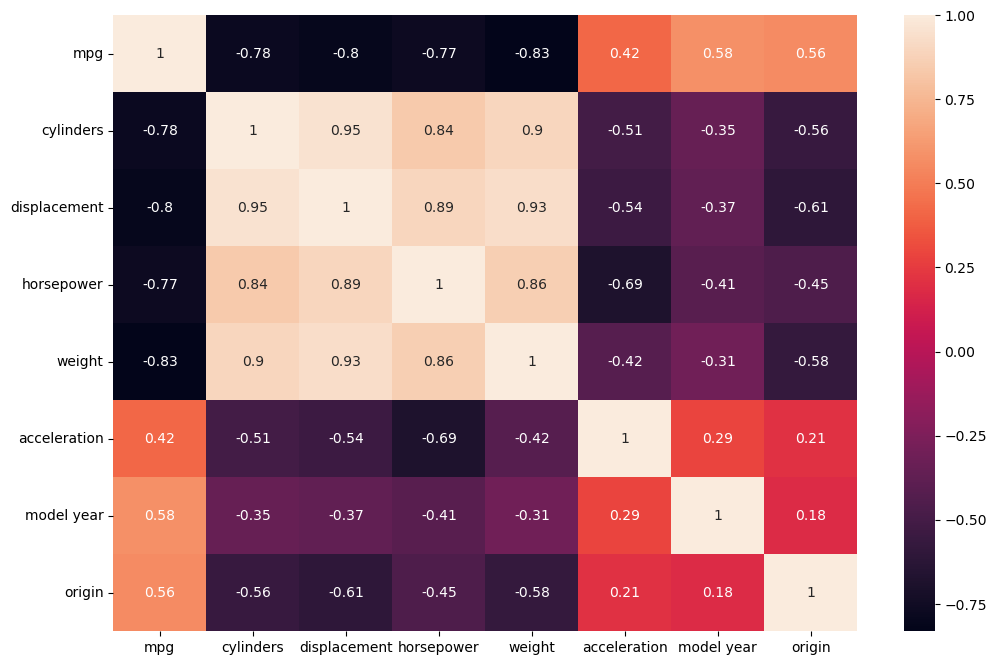

In [17]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True)

### 📊 Understanding Variable Relationships

#### Question 3: Interpreting the Heatmap
The heatmap shows correlations between variables. Let's decode it:

**What We're Looking For:**
   - Which variables correlate strongly with MPG?
   - Which variables might not help predict MPG?
   - Are there any surprising relationships?

**Key Findings:**
   - Your analysis: weight has -0.83 corr with mpg which is strong neg correlation.

#### Question 4: Linear Regression with Weight
Let's test our first relationship:
1. Plot weight vs. MPG
2. Fit a linear model
3. Calculate R² and MSE
4. Visualize the results

Think About:
- Does the relationship look linear?
- How well does the straight line fit?
- Where does the model struggle?

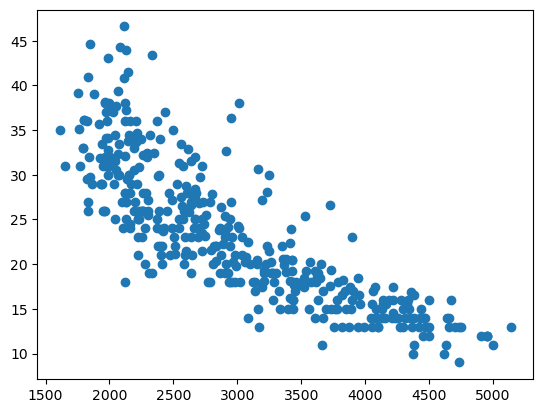

In [18]:
plt.scatter(df["weight"],df["mpg"])
plt.show()

The r2 score: 0.6823565784163479
The MSE score: 17.583533002275946


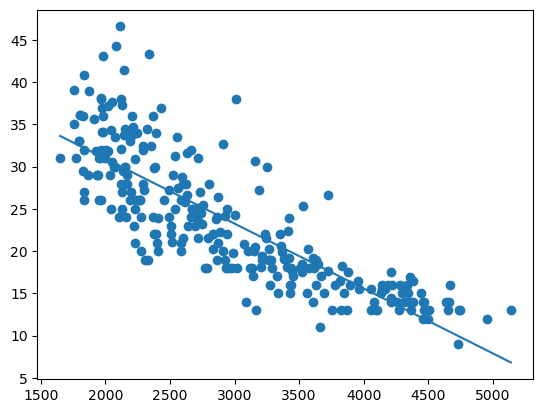

In [19]:
X_train,X_test,y_train,y_test = train_test_split(df["weight"],df["mpg"],test_size=0.3)
model = LinearRegression()
model.fit(X_train.to_numpy().reshape(-1,1),y_train)
print("The r2 score:",model.score(X_train.to_numpy().reshape(-1,1),y_train))
print("The MSE score:",mean_squared_error(model.predict(X_test.to_numpy().reshape(-1,1)),y_test))
plt.scatter(X_train,y_train)
plt.plot([X_train.min(),X_train.max()],[model.predict([[X_train.min()]]),model.predict([[X_train.max()]])])


#### Question 4 - Your analysis:
- even if does look a bit linear and negetive value ...but the dots at the end are slightly curved
- straight line may not capture every details

#### Question 5: Time for Polynomial Regression! 🚀
Let's improve our model:
1. Create a polynomial model
2. Choose a reasonable degree (start with 3)
3. Compare R² and MSE with linear model
4. Look for improvement in the curve fit

Remember: We're looking for a better fit without going too complex! 🎯

The R2 score of the model on the train set is: 0.7032965739088329
The MSE of the model on the test set is: 16.60296080766612


Text(0, 0.5, 'Y')

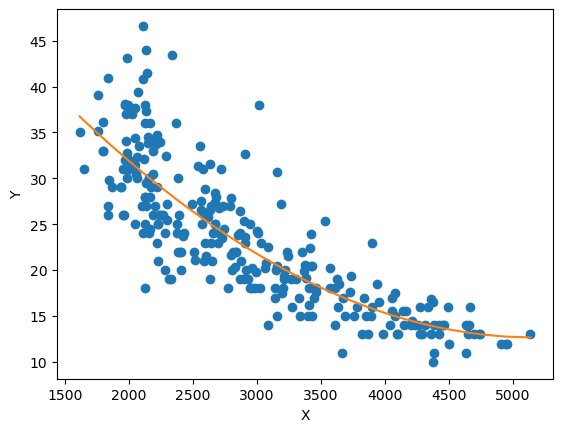

In [20]:
X_train, X_test, y_train, y_test = train_test_split(df["weight"],df['mpg'],test_size=0.3)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree= 3)
model.fit(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train)
print('The R2 score of the model on the train set is:', model.score(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train))
print('The MSE of the model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test.to_numpy().reshape(-1,1))), y_test))
plt.plot(X_train, y_train, 'o')
plt.plot(X_train.sort_values().to_numpy(), model.predict(pol_exp.fit_transform(X_train.sort_values().to_numpy().reshape(-1,1))))
plt.xlabel("X")
plt.ylabel("Y")

Your analysis:
- polynomial feature can capture more complex data than linear...here neg values of weight turned a bit curved
- the r2 score is 72% which means good pred
- mse is 18 which a lower..lower is better when comparing more test set

## 3.4 Model evaluation

### 🎯 Fine-Tuning Our Model

We've made progress, but now comes the crucial part: finding the perfect balance in our model. 

#### Why Model Tuning Matters
1. **Too Simple (Underfitting):**
   - Misses important patterns
   - Poor predictions
   - Low accuracy

2. **Too Complex (Overfitting):**
   - Captures noise in the data
   - Poor generalization
   - Unstable predictions

3. **Just Right (Optimal):**
   - Captures true patterns
   - Good generalization
   - Reliable predictions

Let's find that sweet spot! 🎯

### Question 6: Finding the Optimal Degree 🔍

Let's find the best polynomial degree for our model systematically:

1. **What We'll Do:**
   - Test degrees from 1 to 10
   - Calculate MSE for each degree
   - Plot the results
   - Look for the sweet spot

2. **Watch Out For:**
   - Training vs Testing MSE differences
   - Signs of overfitting
   - The "elbow" in the MSE curve

3. **How to Choose:**
   - Look for lowest test MSE
   - Check if training MSE is much lower
   - Consider model simplicity
   - Remember: simpler is often better!

🚨 **Overfitting Warning Signs:**
- Training MSE much lower than test MSE
- Test MSE starts increasing
- Very complex models (high degrees)

Best degree: 2
Lowest test MSE: 11.826386822994106


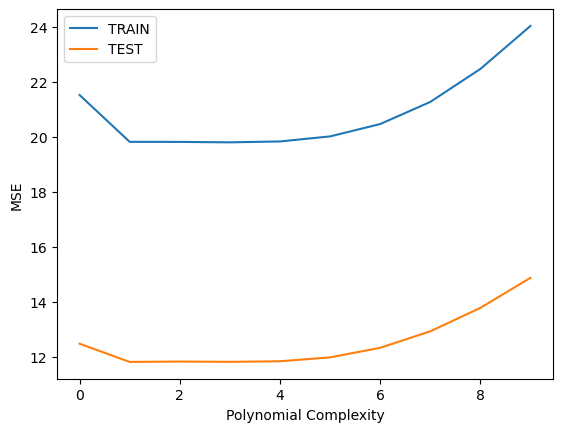

In [21]:
train_mse_errors = []
test_mse_errors = []

X_train, X_test, y_train, y_test = train_test_split(df["weight"],df['mpg'],test_size=0.3)

for d in range(1,11):
    model = LinearRegression()
    pol_exp = PolynomialFeatures(degree=d)
    model.fit(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train)
    
    train_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1))), y_train)
    test_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_test.to_numpy().reshape(-1,1))), y_test)
    
    train_mse_errors.append(train_MSE)
    test_mse_errors.append(test_MSE)

best_degree = np.argmin(test_mse_errors)+1
print("Best degree:", best_degree)
print("Lowest test MSE:", test_mse_errors[best_degree])
plt.plot(train_mse_errors,label='TRAIN')
plt.plot(test_mse_errors,label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("MSE")
plt.legend()

The lowest MSE is at position 2 .., meaning our model will perform best with a degree of 2 ...
- degree 2 curve can bend over just once

In [22]:
X_train, X_test, y_train, y_test = train_test_split(df["weight"], df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree= 3)
model.fit(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train)
print('The R2 score of the model on the train set is:', model.score(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train))
print('The MSE of the model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test.to_numpy().reshape(-1,1))), y_test))

The R2 score of the model on the train set is: 0.6971823051844364
The MSE of the model on the test set is: 14.04581871431077


## 3.5 Excercises

The ans of the questions are above in each sections



##### Question 7: A new car just came on the market with a weight of 2071 pounds. What MPG can we expect of this car?

In [23]:
X_train, X_test, y_train, y_test = train_test_split(df["weight"], df["mpg"], test_size=0.3, random_state=42)

model = LinearRegression()
pol_exp = PolynomialFeatures(degree=2)
model.fit(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train)
model.predict(pol_exp.fit_transform([[2071]]))

array([31.51751698])

##### Question 8: Have another look at the heatmap from section 3.3. Can you spot another variable that might bring an improvement to the model? Figure out the best degree and retrain the model with 'weight' and the added variabele. Calculate $R^2$ and the MSE. Did the model improve?

Another variable that seems likely to have a predictive impact would be displacement. Let's plot this data.

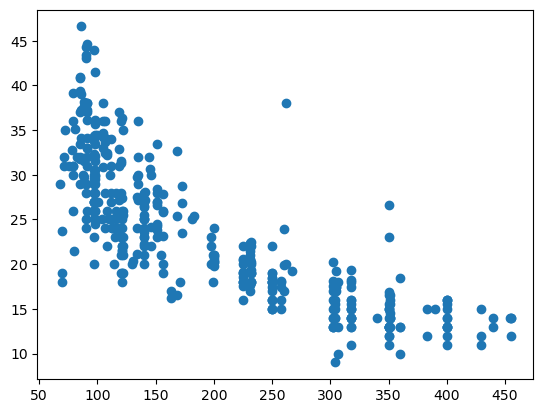

In [24]:
plt.plot(df["displacement"], df["mpg"], 'o')
plt.show()

We can see a curve in this data, meaning polynomial regression will likely result in a good model. To check this, we need to add the parameter to the model, figure out the best degree of the function and retrain the model.

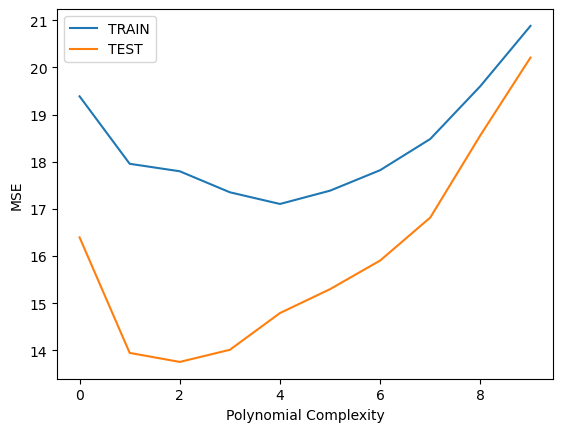

In [25]:
train_mse_errors = []
test_mse_errors = []

X_train, X_test, y_train, y_test = train_test_split(df[["weight","displacement"]], df["mpg"], test_size=0.3, random_state=42)

for d in range(1,11):
    model = LinearRegression()
    pol_exp = PolynomialFeatures(degree=d)
    model.fit(pol_exp.fit_transform(X_train), y_train)
    
    train_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train)
    test_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test)
    
    train_mse_errors.append(train_MSE)
    test_mse_errors.append(test_MSE)

plt.plot(train_mse_errors,label='TRAIN')
plt.plot(test_mse_errors,label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("MSE")
plt.legend()

Interesting! Here we see the lowest MSE is at position 3, or a degree of 4. To see what effect this has on the model, we will retrain it using a degree of 4 and calculate $R^2$ and the MSE.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(df[["weight","displacement"]], df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree=4)
model.fit(pol_exp.fit_transform(X_train), y_train)
print('The R2 score of the model on the train set is:', model.score(pol_exp.fit_transform(X_train), y_train))
print('The MSE of the model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test))

The R2 score of the model on the train set is: 0.7221449582682566
The MSE of the model on the test set is: 14.010485524982577


##### Question 9: Figure out which columns give the best result. Retrain your models as many times as needed using different columns. figure out the best degree and calculate $R^2$ and the MSE. What is the best model you can achieve?

Our first thought would be to train a model using all available data. We will figure out the best degree, then retrain and evaluate the model.

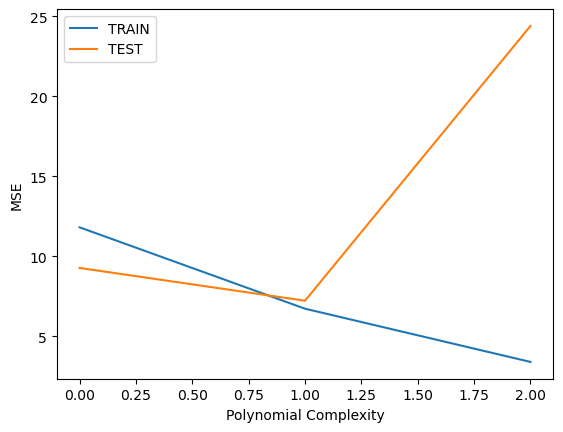

In [27]:
train_mse_errors = []
test_mse_errors = []

X_train, X_test, y_train, y_test = train_test_split(df.drop(['mpg'], axis=1), df["mpg"], test_size=0.3, random_state=42)

for d in range(1,4):
    model = LinearRegression()
    pol_exp = PolynomialFeatures(degree=d)
    model.fit(pol_exp.fit_transform(X_train), y_train)
    
    train_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train)
    test_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test)
    
    train_mse_errors.append(train_MSE)
    test_mse_errors.append(test_MSE)

plt.plot(train_mse_errors,label='TRAIN')
plt.plot(test_mse_errors,label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("MSE")
plt.legend()

In [28]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(['mpg'], axis=1), df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree=2)
model.fit(pol_exp.fit_transform(X_train), y_train)
print('The R2 score of this model on the train set is:', model.score(pol_exp.fit_transform(X_train), y_train))
print('The MSE score of this model on the train set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train))
print('The MSE score of this model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test))

The R2 score of this model on the train set is: 0.8922105030972136
The MSE score of this model on the train set is: 6.7315595781571576
The MSE score of this model on the test set is: 7.228894203488524


We now get an MSE of 7.2. That's great! However, maybe the model is a bit too complex. Let's try reducing the amount of features to see if we can get an even better model.

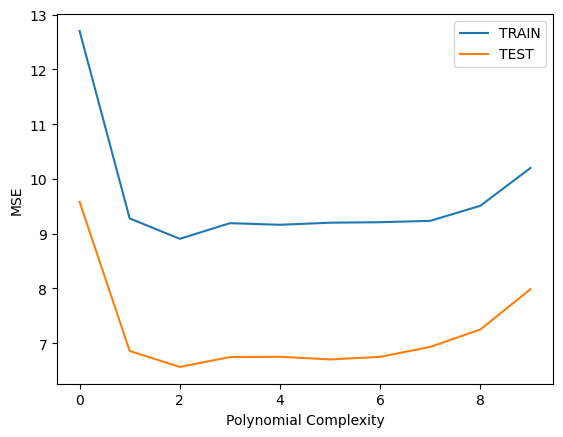

In [29]:
train_mse_errors = []
test_mse_errors = []

X_train, X_test, y_train, y_test = train_test_split(df[["weight","model year"]], df["mpg"], test_size=0.3, random_state=42)

for d in range(1,11):
    model = LinearRegression()
    pol_exp = PolynomialFeatures(degree=d)
    model.fit(pol_exp.fit_transform(X_train), y_train)
    
    train_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train)
    test_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test)
    
    train_mse_errors.append(train_MSE)
    test_mse_errors.append(test_MSE)

plt.plot(train_mse_errors,label='TRAIN')
plt.plot(test_mse_errors,label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("MSE")
plt.legend()

In [30]:
X_train, X_test, y_train, y_test = train_test_split(df[["weight","model year"]], df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree=5)
model.fit(pol_exp.fit_transform(X_train), y_train)
print('The R2 score of this model on the train set is:', model.score(pol_exp.fit_transform(X_train), y_train))
print('The MSE score of this model on the train set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train))
print('The MSE score of this model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test))

The R2 score of this model on the train set is: 0.8532732672268284
The MSE score of this model on the train set is: 9.163228067218272
The MSE score of this model on the test set is: 6.7529041505860565
